# ReAct-агент с нуля

В этом ноутбуке соберём ReAct-агента на LangGraph: модель выбирает инструмент, получает результат и решает, нужен ли ещё один вызов или уже можно ответить пользователю

У агента будет три тула: `get_all_flights` возвращает все рейсы на заданную дату, `geocode_city` находит координаты города, а `get_weather` получает прогноз на дату перелёта по этим координатам через [Open-Meteo](https://open-meteo.com/).

## Подготовка

Перед запуском агента нужно поднять LLM. Ноутбук подключается к уже запущенной модели через OpenAI-совместимый API.

In [ ]:
!pip install -U langgraph langchain-openai requests vllm

### Запуск Qwen через vLLM

Запустите [Qwen/Qwen3-4B-FP8](https://huggingface.co/Qwen/Qwen3-4B-FP8):

```bash
vllm serve Qwen/Qwen3-4B-FP8 \
  --host 127.0.0.1 \
  --port 8000 \
  --served-model-name qwen \
  --max-model-len 8192 \
  --gpu-memory-utilization 0.85 \
  --enable-auto-tool-choice \
  --tool-call-parser hermes \
  --reasoning-parser qwen3
```

In [1]:
LLM_BASE_URL = "http://localhost:8000/v1"
LLM_MODEL = "qwen"
LLM_API_KEY = "EMPTY"

## Создаём ReAct-агента

### Состояние графа

Состояние хранит историю сообщений: запросы пользователя, ответы модели и результаты вызова инструментов. При необходимости сюда можно добавить другие поля.

In [2]:
from typing import Annotated, Sequence, TypedDict

from langchain_core.messages import BaseMessage
from langgraph.graph.message import add_messages


class AgentState(TypedDict):
    """Состояние агента с историей сообщений."""

    messages: Annotated[Sequence[BaseMessage], add_messages]

### Два инструмента для получения погоды

Декоратор `@tool` превращает функцию в инструмент: модель увидит его имя, описание и схему аргументов. `bind_tools` передаёт модели эти описания; сам Python-код выполняется позже, в узле `tools`.

Получение погоды реализовано через два отдельных действия:

1. `geocode_city(location)` обращается к [API геокодирования](https://open-meteo.com/en/docs/geocoding-api) и возвращает все найденные варианты (до 100): город, страну, регион, широту и долготу.
2. `get_weather(latitude, longitude, date)` обращается к [погодному API](https://open-meteo.com/en/docs) и возвращает суточный прогноз на заданную дату: минимальную и максимальную температуру, сумму и максимальную вероятность осадков, максимальную скорость ветра и погодные условия.


In [3]:
import datetime as dt
import json

import requests
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI

WEATHER_DESCRIPTIONS = {
    0: "Clear sky",
    1: "Mainly clear",
    2: "Partly cloudy",
    3: "Overcast",
    45: "Fog",
    48: "Depositing rime fog",
    51: "Light drizzle",
    53: "Moderate drizzle",
    55: "Dense drizzle",
    56: "Light freezing drizzle",
    57: "Dense freezing drizzle",
    61: "Slight rain",
    63: "Moderate rain",
    65: "Heavy rain",
    66: "Light freezing rain",
    67: "Heavy freezing rain",
    71: "Slight snow fall",
    73: "Moderate snow fall",
    75: "Heavy snow fall",
    77: "Snow grains",
    80: "Slight rain showers",
    81: "Moderate rain showers",
    82: "Violent rain showers",
    85: "Slight snow showers",
    86: "Heavy snow showers",
    95: "Slight or moderate thunderstorm",
    96: "Thunderstorm with slight hail",
    99: "Thunderstorm with heavy hail",
}


@tool
def geocode_city(location: str) -> dict:
    """Найди все варианты города и их координаты через Open-Meteo (до 100 результатов).

    Args:
        location: Название города в именительном падеже, например «Санкт-Петербург».
            Передавай только название города, без дополнительных слов.
    """
    location = location.strip()
    if not location:
        return {"error": "Укажите название города."}

    try:
        response = requests.get(
            "https://geocoding-api.open-meteo.com/v1/search",
            params={"name": location, "count": 100, "language": "ru", "format": "json"},
        )
        response.raise_for_status()
        places = response.json().get("results", [])
        if not places:
            return {"error": f"Город «{location}» не найден. Уточните название."}
        return {
            "results": [
                {
                    "location": place["name"],
                    "region": place.get("admin1", ""),
                    "country": place.get("country", ""),
                    "latitude": place["latitude"],
                    "longitude": place["longitude"],
                }
                for place in places
            ],
            "source": "https://open-meteo.com/",
        }
    except requests.RequestException:
        return {"error": "Не удалось найти координаты: ошибка HTTP или тайм-аут Open-Meteo."}
    except (ValueError, KeyError, TypeError):
        return {"error": "API геокодирования вернул ответ в неожиданном формате."}


@tool
def get_weather(latitude: float, longitude: float, date: str) -> dict:
    """Получи суточный прогноз погоды по координатам на указанную дату.

    Для города сначала вызови geocode_city, выбери подходящий вариант из results
    и используй его координаты. Если выбор неоднозначен, уточни город у пользователя.
    Прогноз доступен только в пределах горизонта Open-Meteo, до 16 дней.

    Args:
        latitude: Широта от -90 до 90 из результата geocode_city или запроса пользователя.
        longitude: Долгота от -180 до 180 из результата geocode_city или запроса пользователя.
        date: Дата прогноза в формате YYYY-MM-DD; для поездки совпадает с датой билета.
    """
    if not (-90 <= latitude <= 90 and -180 <= longitude <= 180):
        return {"error": "Широта должна быть от -90 до 90, долгота — от -180 до 180."}
    try:
        forecast_date = dt.date.fromisoformat(date).isoformat()
    except ValueError:
        return {"error": "Передайте дату прогноза в формате YYYY-MM-DD."}

    try:
        response = requests.get(
            "https://api.open-meteo.com/v1/forecast",
            params={
                "latitude": latitude,
                "longitude": longitude,
                "start_date": forecast_date,
                "end_date": forecast_date,
                "daily": (
                    "weather_code,temperature_2m_min,temperature_2m_max,"
                    "precipitation_sum,precipitation_probability_max,wind_speed_10m_max"
                ),
                "temperature_unit": "celsius",
                "wind_speed_unit": "kmh",
                "precipitation_unit": "mm",
                "timezone": "auto",
            },
        )
        if response.status_code == 400:
            reason = response.json().get("reason", "Дата вне доступного диапазона прогноза.")
            return {"error": f"Прогноз на {forecast_date} недоступен: {reason}"}
        response.raise_for_status()
        weather = response.json()
        daily = weather["daily"]

        if daily["time"] != [forecast_date]:
            return {"error": f"Open-Meteo не вернул прогноз на {forecast_date}."}
        forecast = {name: values[0] for name, values in daily.items() if name != "time"}
        return {
            "latitude": latitude,
            "longitude": longitude,
            "date": forecast_date,
            "timezone": weather["timezone"],
            "forecast": forecast,
            "units": weather["daily_units"],
            "description": WEATHER_DESCRIPTIONS.get(
                forecast["weather_code"], "неизвестный код погодных условий"
            ),
            "source": "https://open-meteo.com/",
        }
    except requests.RequestException:
        return {"error": "Не удалось получить прогноз: ошибка HTTP или тайм-аут Open-Meteo."}
    except (ValueError, KeyError, TypeError, IndexError):
        return {"error": "Погодный API вернул ответ в неожиданном формате."}


### Все рейсы на заданную дату

Тул `get_all_flights(date)` принимает только дату в формате `YYYY-MM-DD` и возвращает шесть фиксированных рейсов по разным маршрутам. Для любой даты набор рейсов и цены одинаковые; дата подставляется в результат.

Зарегистрируем все три инструмента через `bind_tools`.

In [4]:
import datetime as dt
from zoneinfo import ZoneInfo


DUMMY_FLIGHTS = [
    {"flight_number": "SU-100", "origin": "Москва", "destination": "Санкт-Петербург",
     "departure_time": "08:00", "arrival_time": "09:30", "price": 5200},
    {"flight_number": "DP-200", "origin": "Москва", "destination": "Санкт-Петербург",
     "departure_time": "13:00", "arrival_time": "14:40", "price": 3800},
    {"flight_number": "S7-300", "origin": "Москва", "destination": "Санкт-Петербург",
     "departure_time": "19:00", "arrival_time": "20:35", "price": 6100},
    {"flight_number": "DP-201", "origin": "Санкт-Петербург", "destination": "Москва",
     "departure_time": "10:00", "arrival_time": "11:40", "price": 1800},
    {"flight_number": "SU-400", "origin": "Москва", "destination": "Казань",
     "departure_time": "12:00", "arrival_time": "13:40", "price": 2500},
    {"flight_number": "S7-500", "origin": "Казань", "destination": "Санкт-Петербург",
     "departure_time": "16:00", "arrival_time": "18:15", "price": 2900},
]


@tool
def get_all_flights(date: str) -> dict:
    """Получи все авиарейсы на указанную дату.

    Args:
        date: Дата вылета в формате YYYY-MM-DD.
    """
    try:
        departure_date = dt.date.fromisoformat(date).isoformat()
    except ValueError:
        return {"error": "Передайте дату вылета в формате YYYY-MM-DD."}

    return {
        "date": departure_date,
        "timezone": "Europe/Moscow",
        "currency": "RUB",
        "flights": DUMMY_FLIGHTS,
    }


tools = [geocode_city, get_weather, get_all_flights]
model = ChatOpenAI(
    base_url=LLM_BASE_URL,
    model=LLM_MODEL,
    api_key=LLM_API_KEY,
    temperature=0,
).bind_tools(tools)

### Проверяем инструменты отдельно

In [5]:
tomorrow = (dt.datetime.now(ZoneInfo("Europe/Moscow")).date() + dt.timedelta(days=1)).isoformat()
print(json.dumps(
    get_all_flights.invoke({"date": tomorrow}),
    ensure_ascii=False,
    indent=2,
))

places = geocode_city.invoke({"location": "Санкт-Петербург"})
print(json.dumps(places, ensure_ascii=False, indent=2))
if "error" not in places:
    # Для примера получаем погоду для первого из выведенных вариантов.
    place = places["results"][0]
    weather = get_weather.invoke({
        "latitude": place["latitude"],
        "longitude": place["longitude"],
        "date": tomorrow,
    })
    print(json.dumps(weather, ensure_ascii=False, indent=2))

{
  "date": "2026-11-21",
  "timezone": "Europe/Moscow",
  "currency": "RUB",
  "flights": [
    {
      "flight_number": "SU-100",
      "origin": "Москва",
      "destination": "Санкт-Петербург",
      "departure_time": "08:00",
      "arrival_time": "09:30",
      "price": 5200
    },
    {
      "flight_number": "DP-200",
      "origin": "Москва",
      "destination": "Санкт-Петербург",
      "departure_time": "13:00",
      "arrival_time": "14:40",
      "price": 3800
    },
    {
      "flight_number": "S7-300",
      "origin": "Москва",
      "destination": "Санкт-Петербург",
      "departure_time": "19:00",
      "arrival_time": "20:35",
      "price": 6100
    },
    {
      "flight_number": "DP-201",
      "origin": "Санкт-Петербург",
      "destination": "Москва",
      "departure_time": "10:00",
      "arrival_time": "11:40",
      "price": 1800
    },
    {
      "flight_number": "SU-400",
      "origin": "Москва",
      "destination": "Казань",
      "departure_time": "12

### Узлы и переходы

В нашем графе два узла:

- `agent` вызывает модель с текущей историей сообщений;
- `tools` исполняет инструменты, выбранные моделью, и добавляет их результаты в историю.

Функция `should_continue` проверяет ответ модели. Если в нём есть вызовы инструментов, граф идёт в `tools`, а затем возвращается в `agent`. Если вызовов нет, выполнение завершается.

Для каждого вызова инструмента возвращаем `ToolMessage` с тем же `tool_call_id`, чтобы модель могла сопоставить результат с запросом. Здесь мы пишем упрощённый аналог готового узла [ToolNode](https://docs.langchain.com/oss/python/langgraph/workflows-agents).

In [6]:
import json

from langchain_core.messages import SystemMessage, ToolMessage
from langchain_core.runnables import RunnableConfig

tools_by_name = {tool.name: tool for tool in tools}


def tool_node(state: AgentState):
    """Выполняем все вызовы инструментов из последнего ответа модели."""
    outputs = []
    for tool_call in state["messages"][-1].tool_calls:
        tool_result = tools_by_name[tool_call["name"]].invoke(tool_call["args"])
        outputs.append(
            ToolMessage(
                content=json.dumps(tool_result, ensure_ascii=False),
                name=tool_call["name"],
                tool_call_id=tool_call["id"],
            )
        )
    return {"messages": outputs}


def make_system_message():
    """Одна и та же системная инструкция для агента и просмотра промпта."""
    today = dt.datetime.now(ZoneInfo("Europe/Moscow")).date().isoformat()
    return SystemMessage(
        f"Отвечай кратко и по-русски. Сегодня {today} (Europe/Moscow); "
        "относительные даты считай от неё, формат дат — YYYY-MM-DD. "
        "Если данных не хватает — уточни; ошибки сообщай, данные не выдумывай."
    )


def call_model(state: AgentState, config: RunnableConfig):
    """Вызываем модель с системной инструкцией и накопленной историей."""
    response = model.invoke([make_system_message()] + list(state["messages"]), config)
    return {"messages": [response]}


def should_continue(state: AgentState):
    """Продолжаем цикл, только если модель запросила инструменты."""
    if state["messages"][-1].tool_calls:
        return "continue"
    return "end"

### Что передаём LLM: system prompt и tools

Сначала посмотрим на поля запроса к OpenAI-совместимому API. Системная инструкция идёт первым сообщением с ролью `system`, а описания инструментов — отдельным полем `tools`. Берём схемы из `model.kwargs`, куда их уже записал `bind_tools`: это имена, описания и JSON Schema аргументов, без Python-кода функций.

In [7]:
preview_messages = [
    {"role": "system", "content": make_system_message().content},
    {"role": "user", "content": "Какие есть рейсы из Москвы в Петербург на завтра?"},
]
request_preview = {
    "model": LLM_MODEL,
    "messages": preview_messages,
    "tools": model.kwargs["tools"],
    "temperature": 0,
}
print(json.dumps(request_preview, ensure_ascii=False, indent=2))


{
  "model": "qwen",
  "messages": [
    {
      "role": "system",
      "content": "Отвечай кратко и по-русски. Сегодня 2026-11-20 (Europe/Moscow); относительные даты считай от неё, формат дат — YYYY-MM-DD. Если данных не хватает — уточни; ошибки сообщай, данные не выдумывай."
    },
    {
      "role": "user",
      "content": "Какие есть рейсы из Москвы в Петербург на завтра?"
    }
  ],
  "tools": [
    {
      "type": "function",
      "function": {
        "name": "geocode_city",
        "description": "Найди все варианты города и их координаты через Open-Meteo (до 100 результатов).\n\nArgs:\n    location: Название города в именительном падеже, например «Санкт-Петербург».\n        Передавай только название города, без дополнительных слов.",
        "parameters": {
          "properties": {
            "location": {
              "type": "string"
            }
          },
          "required": [
            "location"
          ],
          "type": "object"
        }
      }
    

#### Как это выглядит в chat template Qwen

На стороне vLLM токенизатор собирает сообщения и описания инструментов в единый текст по **chat template** модели. Следующая необязательная ячейка показывает этот текст для Qwen из инструкции запуска: специальные токены ролей, блок `<tools>` со схемами и системную инструкцию. Шаблон также объясняет модели формат ответа `<tool_call>`.

In [8]:
from transformers import AutoTokenizer

preview_tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-4B-FP8")
rendered_prompt = preview_tokenizer.apply_chat_template(
    request_preview["messages"],
    tools=request_preview["tools"],
    tokenize=False,
    add_generation_prompt=True,
)
print(rendered_prompt)

<|im_start|>system
Отвечай кратко и по-русски. Сегодня 2026-11-20 (Europe/Moscow); относительные даты считай от неё, формат дат — YYYY-MM-DD. Если данных не хватает — уточни; ошибки сообщай, данные не выдумывай.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "geocode_city", "description": "Найди все варианты города и их координаты через Open-Meteo (до 100 результатов).\n\nArgs:\n    location: Название города в именительном падеже, например «Санкт-Петербург».\n        Передавай только название города, без дополнительных слов.", "parameters": {"properties": {"location": {"type": "string"}}, "required": ["location"], "type": "object"}}}
{"type": "function", "function": {"name": "get_weather", "description": "Получи суточный прогноз погоды по координатам на указанную дату.\n\nДля города сначала вызови geocode_city, выбери подходящий вари

### Собираем граф

Создадим граф состояния, зарегистрируем узлы и зададим переходы:

`начало → agent → tools → agent → … → конец`

Условный переход из `agent` выбирает между вызовом инструментов и завершением. Из `tools` всегда возвращаемся в `agent`, чтобы модель прочитала результат и сформулировала ответ.

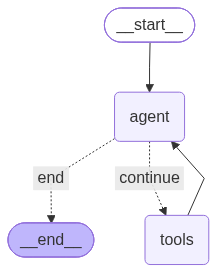

In [9]:
from langgraph.graph import END, StateGraph

workflow = StateGraph(AgentState)
workflow.add_node("agent", call_model)
workflow.add_node("tools", tool_node)
workflow.set_entry_point("agent")

# Результат should_continue определяет следующий шаг.
workflow.add_conditional_edges(
    "agent",
    should_continue,
    {"continue": "tools", "end": END},
)
workflow.add_edge("tools", "agent")
graph = workflow.compile()

# Схема полезна для отладки, но для работы агента не обязательна.
# Отрисовка PNG может потребовать доступа к внешнему сервису Mermaid.
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print("Не удалось нарисовать PNG. Текстовое описание графа:")
    print(graph.get_graph().draw_mermaid())

## Запускаем агента

In [11]:
def print_stream(stream):
    """Выводим все новые сообщения от каждого узла, включая все результаты tools."""
    for update in stream:
        for node_update in update.values():
            for message in node_update.get("messages", []):
                message.pretty_print()


query = (
    "Найди самый дешёвый билет из Москвы в Казань на завтра "
    "и узнай прогноз погоды на эту дату"
)
print("Запрос пользователя:", query)
inputs = {"messages": [("user", query)]}
print_stream(
    graph.stream(inputs, config={"recursion_limit": 10}, stream_mode="updates")
)

Запрос пользователя: Найди самый дешёвый билет из Москвы в Казань на завтра и узнай прогноз погоды на эту дату
================================== Ai Message ==================================
Tool Calls:
  get_all_flights (chatcmpl-tool-a791c6ad6768aaa2)
 Call ID: chatcmpl-tool-a791c6ad6768aaa2
  Args:
    date: 2026-11-21
  geocode_city (chatcmpl-tool-9cfdc74acac4f9d2)
 Call ID: chatcmpl-tool-9cfdc74acac4f9d2
  Args:
    location: Москва
  geocode_city (chatcmpl-tool-bd41491a9c621790)
 Call ID: chatcmpl-tool-bd41491a9c621790
  Args:
    location: Казань
  get_weather (chatcmpl-tool-b7de725ffbaf2a98)
 Call ID: chatcmpl-tool-b7de725ffbaf2a98
  Args:
    latitude: 55.7558
    longitude: 37.6176
    date: 2026-11-21
  get_weather (chatcmpl-tool-b22478859aa2ad8d)
 Call ID: chatcmpl-tool-b22478859aa2ad8d
  Args:
    latitude: 56.8063
    longitude: 44.4291
    date: 2026-11-21
================================= Tool Message =================================
Name: get_all_flights

{"date": "2

## Диалог с агентом

Запустите ячейку и вводите сообщения. Например, сначала попросите найти рейсы, а затем уточните: «А какая там будет погода?». Для выхода введите `/exit`.

В `history` держим всю переписку, включая вызовы инструментов и их результаты, и передаём её графу с каждым новым вопросом. Так мы реализовали **краткосрочную память** в рамках диалога: агент учитывает предыдущие сообщения и понимает уточнения пользователя.

In [13]:
from langchain_core.messages import HumanMessage

history = []
print("Диалог с агентом. Для выхода введите /exit.")

while True:
    try:
        query = input("Вы: ").strip()
    except (EOFError, KeyboardInterrupt):
        print("\nДиалог завершён.")
        break

    if query == "/exit":
        break
    if not query:
        continue

    history = add_messages(history, [HumanMessage(content=query)])
    for update in graph.stream(
        {"messages": history},
        config={"recursion_limit": 10},
        stream_mode="updates",
    ):
        for node_update in update.values():
            new_messages = node_update.get("messages", [])
            history = add_messages(history, new_messages)
            for message in new_messages:
                message.pretty_print()

Диалог с агентом. Для выхода введите /exit.
Вы: найди рейс на 22.11 с казани в Санкт-Петербург
================================== Ai Message ==================================
Tool Calls:
  get_all_flights (chatcmpl-tool-b934ea901e6b81c6)
 Call ID: chatcmpl-tool-b934ea901e6b81c6
  Args:
    date: 2026-11-22
================================= Tool Message =================================
Name: get_all_flights

{"date": "2026-11-22", "timezone": "Europe/Moscow", "currency": "RUB", "flights": [{"flight_number": "SU-100", "origin": "Москва", "destination": "Санкт-Петербург", "departure_time": "08:00", "arrival_time": "09:30", "price": 5200}, {"flight_number": "DP-200", "origin": "Москва", "destination": "Санкт-Петербург", "departure_time": "13:00", "arrival_time": "14:40", "price": 3800}, {"flight_number": "S7-300", "origin": "Москва", "destination": "Санкт-Петербург", "departure_time": "19:00", "arrival_time": "20:35", "price": 6100}, {"flight_number": "DP-201", "origin": "Санкт-Петербург